In [14]:
from collections import Counter
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import make_pipeline
from imblearn.metrics import classification_report_imbalanced
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from imblearn.under_sampling import RandomUnderSampler
from sklearn.inspection import permutation_importance
import altair as alt

In [15]:
# data = pd.read_csv("/content/seurat_hca_h1_0.9_df_no_features.csv")
data = pd.read_csv("/content/seurat_hca_h1_0.9_df_no_features_less_diff.csv")

In [16]:
filtered_data = data[data["cell_type"].isin(["HSC", "ProB", "MPP", "PreB", "GMP", "CLP", "ERP", "MEP", "MDP", "MKP", "Eo/B/Mast"])]

counter = Counter(filtered_data["cell_type"])
print(counter)

Counter({'HSC': 228, 'MPP': 199, 'PreB': 189, 'ERP': 186, 'ProB': 147, 'GMP': 115, 'MKP': 41, 'MDP': 38, 'MEP': 34, 'CLP': 31, 'Eo/B/Mast': 12})


In [17]:
filtered_data = data[data["cell_type"].isin(['HSC', 'MPP', 'PreB', 'ERP', 'ProB', 'GMP'])]

In [18]:
X = filtered_data.drop(columns=["cell_type", "cell_barcode"])  # Features (gene expression)
y = filtered_data["cell_type"]  # Target (cell_type)

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

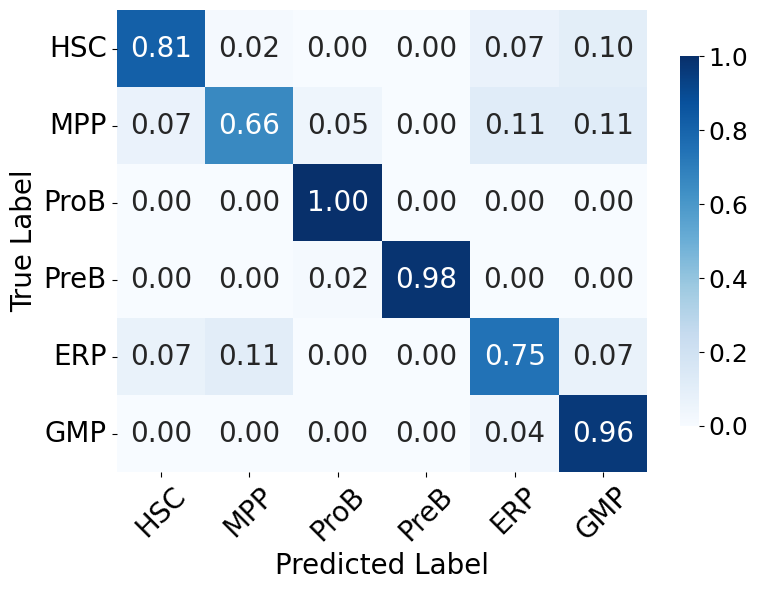

In [22]:
pipeline = make_pipeline(
    RandomUnderSampler(random_state=42),   # Undersampling
    RandomForestClassifier(n_estimators=150, random_state=42)  # Random Forest
)

pipeline.fit(X_train, y_train)

# Make predictions
y_pred = pipeline.predict(X_test)

# Define label order

desired_order = ["HSC", "MPP", "ProB", "PreB", "ERP", "GMP"]

# 1. Compute confusion matrix using 'labels' to ensure fixed shape (13x13)
# This handles cases where a class might be missing from y_test or y_pred
cm = confusion_matrix(y_test, y_pred, labels=desired_order)

# 2. Normalize
# Add a small epsilon or handle division by zero for classes with 0 samples in y_test
cm_normalized = cm.astype(float) / (cm.sum(axis=1, keepdims=True) + 1e-10)

# 3. Create DataFrame using desired_order directly
cm_df = pd.DataFrame(cm_normalized, index=desired_order, columns=desired_order)

# Calculate recall per cell type
recall_df = pd.DataFrame({"Cell_type": desired_order, "Recall": np.diag(cm_df.loc[desired_order, desired_order].values)})

# Export to CSV
recall_df.to_csv("/content/HCA_recall_per_cell_type.csv", index=False)

# 4. Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(cm_df, annot=True, fmt='.2f', cmap='Blues', xticklabels=desired_order, yticklabels=desired_order, annot_kws={"size": 20},
        vmin=0, vmax=1, cbar_kws={"shrink": 0.8})
# Titles and axis labels
plt.xlabel("Predicted Label", fontsize=20)
plt.ylabel("True Label", fontsize=20)
# plt.title("Xpand", fontsize=20, fontweight="bold")
# Axis tick label sizes
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, fontsize=20)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=20)
# Access the colorbar and change number size
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=18)
plt.tight_layout()
plt.savefig("/content/confusion_matrix_hca_no_features_less_diff_dani.pdf", bbox_inches="tight")
plt.show()

/tmp/ipykernel_1022/3277037188.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), fontsize=14)


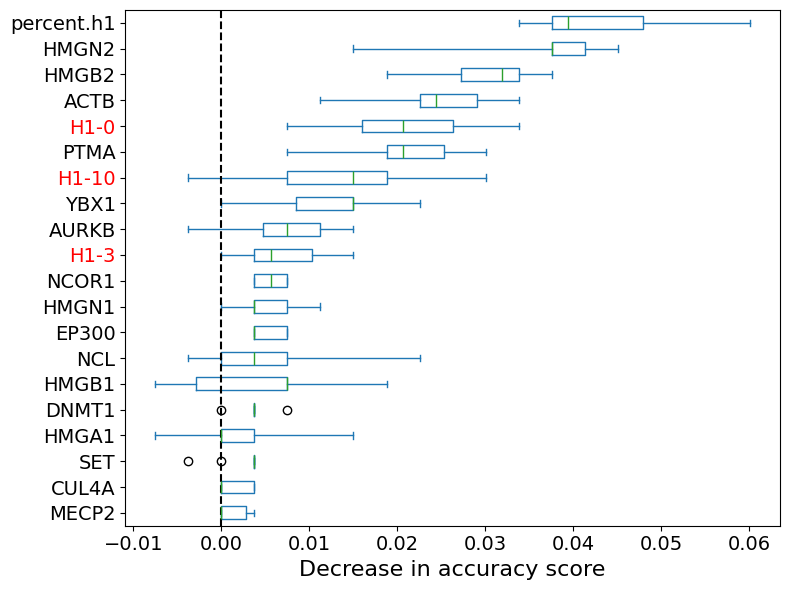

In [20]:
feature_names = X_train.columns.tolist()
rf_model = pipeline.named_steps["randomforestclassifier"]

result = permutation_importance(
    rf_model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2
)
forest_importances = pd.Series(result.importances_mean, index=feature_names)

# Sort indices by importance (ascending)
sorted_importances_idx = result.importances_mean.argsort()

# Slice to get only the top 20 features (the last 20 elements)
top_20_idx = sorted_importances_idx[-20:]

# Create the DataFrame for the plot using only the top 20 indices
importances = pd.DataFrame(
    result.importances[top_20_idx].T,
    columns=X.columns[top_20_idx],
)

h1_genes = {"H1-0", "H1-1", "H1-2", "H1-3", "H1-4", "H1-5", "H1-10"}

# Create the plot
# (You can reduce the figsize height here if you want since there are fewer features now)
fig, ax = plt.subplots(figsize=(8, 6))  # Increase height
importances.plot.box(vert=False, whis=10, ax=ax)

# Highlight H1 genes in red
labels = ax.get_yticklabels()
for label in labels:
    if label.get_text() in h1_genes:
        label.set_color("red")

# Additional formatting
# ax.set_title("Permutation Importances")
# plt.title("Xpand", fontsize=16, fontweight="bold")
ax.axvline(x=0, color="k", linestyle="--")
ax.set_xlabel("Decrease in accuracy score", fontsize=16)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=14)
ax.set_xticklabels(ax.get_xticklabels(), fontsize=14)
fig.tight_layout()
plt.savefig("/content/permutation_importances_hca_top20_no_features_less_diff.pdf", bbox_inches="tight")
plt.show()

In [23]:
# Build a table with the permutation importance order and mean importance for every gene
importance_table = pd.DataFrame({
    "gene": feature_names,
    "mean_importance": result.importances_mean,
})

# Rank genes from highest to lowest mean importance
importance_table["importance_order"] = (
    importance_table["mean_importance"].rank(method="first", ascending=False).astype(int)
)

# Sort by importance order
importance_table = importance_table.sort_values("importance_order")[["gene", "importance_order", "mean_importance"]]

# Save the full table to the provided folder
output_path = "/content/tabla_dani_no_features_less_diff.csv"
importance_table.to_csv(output_path, index=False)

# Display the table
importance_table

,gene,importance_order,mean_importance
78,percent.h1,1,0.042857
1,HMGN2,2,0.037594
18,HMGB2,3,0.030827
36,ACTB,4,0.023684
75,H1-0,5,0.021053
...,...,...,...
28,H1-5,75,-0.002632
56,UBE2N,76,-0.002632
42,HMGB3,77,-0.002632
49,PFKP,78,-0.003008
